# DSCI 552: Homework 5

Name: Hanwen Zhang  
GitHub Username: zhw123456789  
USC ID: 4602764147

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold,
                                     cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBRegressor

pd.set_option("display.precision", 5)
pd.set_option("display.max_rows", 150)

## 1(a) Acute Inflammations data

[UCI dataset](https://archive.ics.uci.edu/dataset/184/acute+inflammations).
Binary values are encoded as 0 = no and 1 = yes. Each pair of diagnoses is treated as one class.

In [2]:
acute_columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
                 "micturition_pain", "burning", "bladder", "nephritis"]
acute = pd.read_csv("../data/diagnosis.data", sep="\t", encoding="utf-16",
                    decimal=",", header=None, names=acute_columns)
for column in acute_columns[1:]:
    acute[column] = acute[column].map({"no": 0, "yes": 1})

X_acute = acute.iloc[:, :6]
diagnosis = 2 * acute["bladder"] + acute["nephritis"]
y_acute = diagnosis.map({0: "Neither", 1: "Nephritis",
                         2: "Bladder inflammation", 3: "Both"})
display(acute.head())
display(y_acute.value_counts().to_frame("Count"))

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,burning,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


,Count
Bladder inflammation,40
Nephritis,31
Neither,30
Both,19


## 1(b) Decision tree

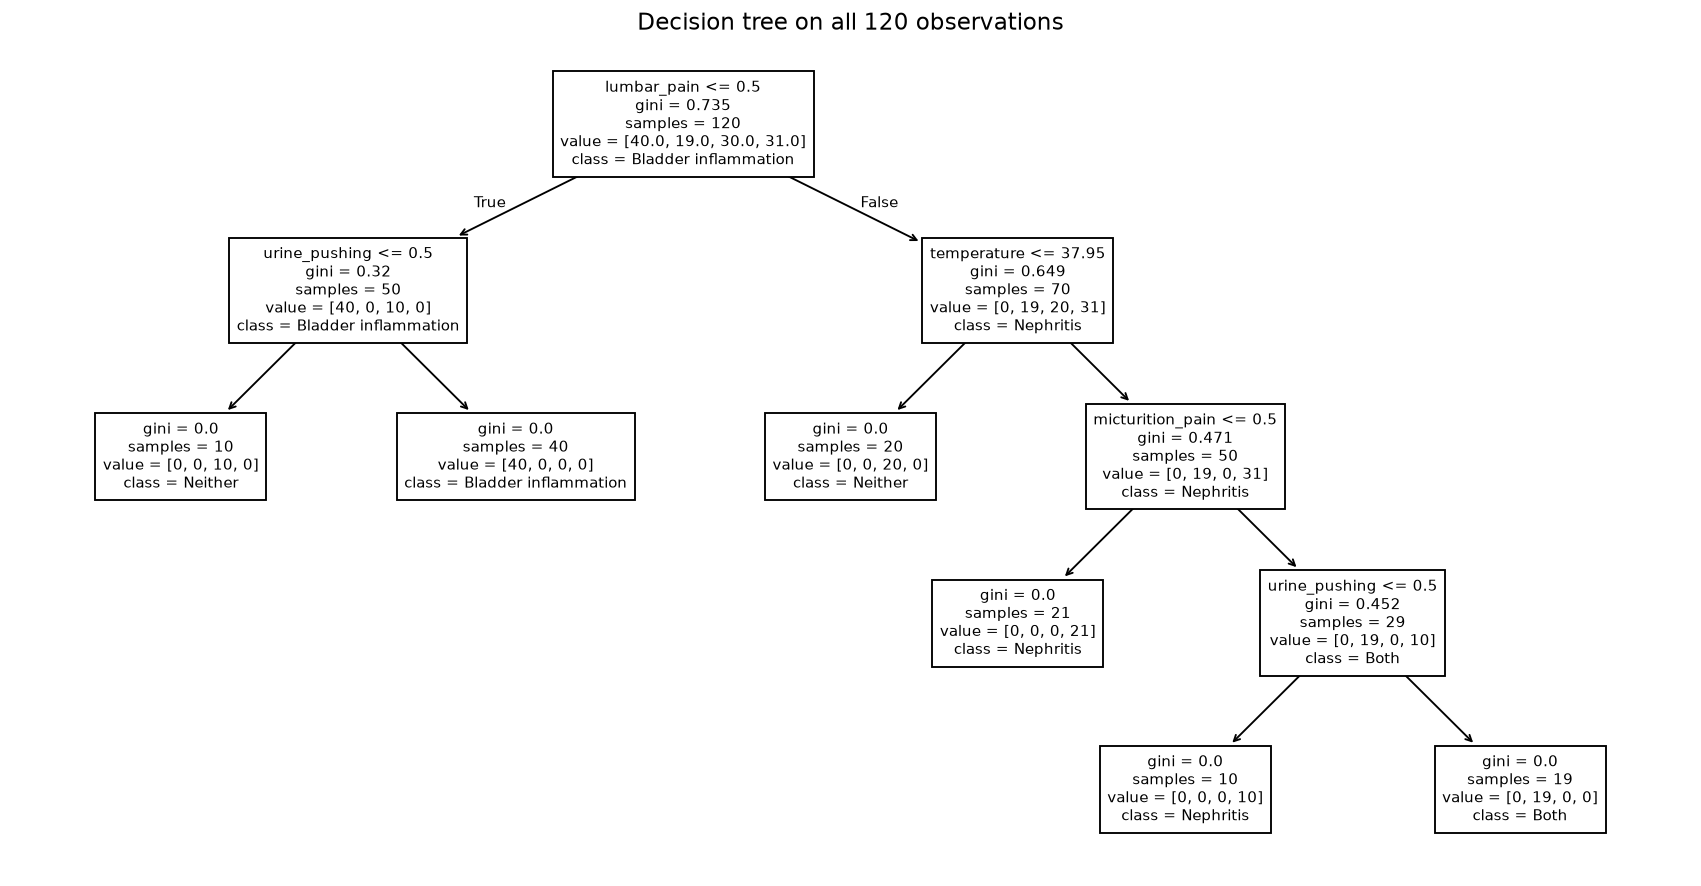

In [3]:
full_tree = DecisionTreeClassifier(random_state=552)
full_tree.fit(X_acute, y_acute)

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(full_tree, feature_names=X_acute.columns,
          class_names=full_tree.classes_, filled=False, fontsize=8, ax=ax)
ax.set_title("Decision tree on all 120 observations")
plt.show()

## 1(c) IF-THEN rules

In [4]:
def print_rules(model, node=0, conditions=()):
    tree = model.tree_
    if tree.children_left[node] == tree.children_right[node]:
        label = model.classes_[tree.value[node][0].argmax()]
        print("IF " + " AND ".join(conditions) + " THEN " + label)
        return

    feature = X_acute.columns[tree.feature[node]]
    threshold = tree.threshold[node]
    left = f"{feature} <= {threshold:.2f}"
    right = f"{feature} > {threshold:.2f}"
    print_rules(model, tree.children_left[node], conditions + (left,))
    print_rules(model, tree.children_right[node], conditions + (right,))

print_rules(full_tree)

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder inflammation
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain <= 0.50 THEN Nephritis
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing <= 0.50 THEN Nephritis
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pain > 0.50 AND urine_pushing > 0.50 THEN Both


## 1(d) Cost-complexity pruning

,alpha,Depth,Leaves,Training accuracy,CV accuracy
0,0.00000,4,6,1.00000,0.99167
1,0.09817,2,4,0.84167,0.85833
2,0.13333,2,3,0.75833,0.76667
3,0.18200,1,2,0.59167,0.67500
4,0.22292,0,1,0.33333,0.48333


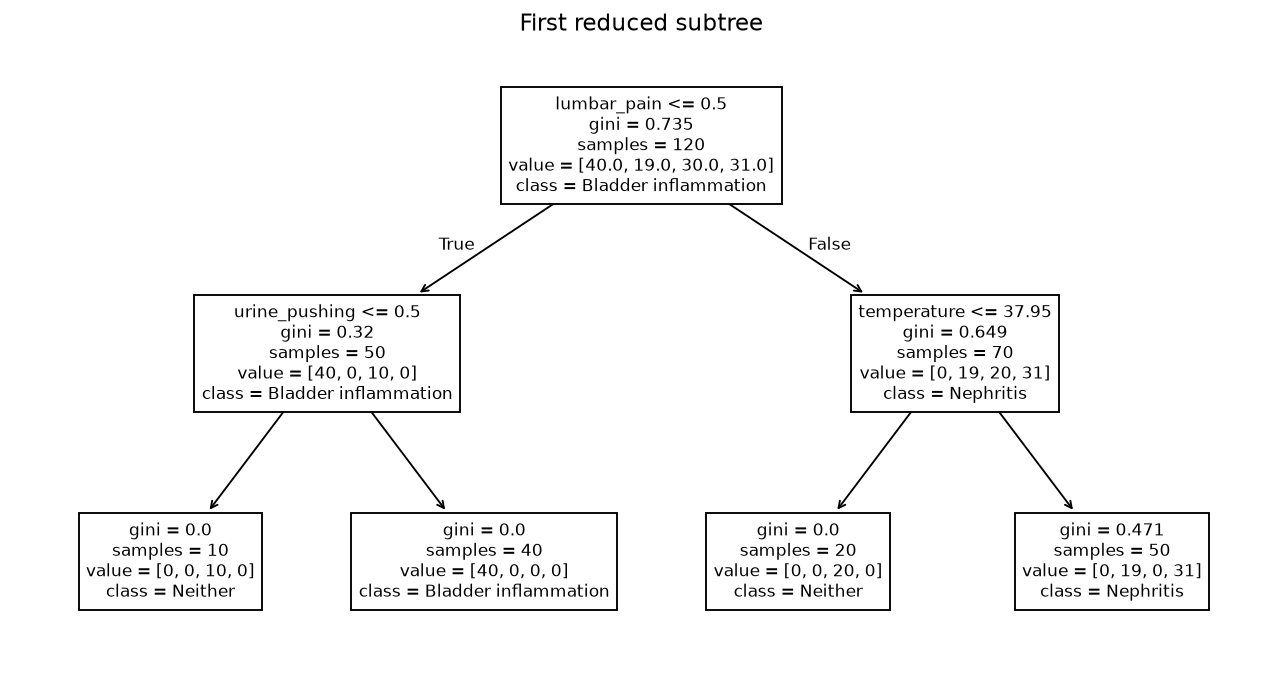

IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Neither
IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder inflammation
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Neither
IF lumbar_pain > 0.50 AND temperature > 37.95 THEN Nephritis


In [5]:
alphas = full_tree.cost_complexity_pruning_path(X_acute, y_acute).ccp_alphas
tree_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
pruning_rows = []
trees = []
for alpha in alphas:
    tree = DecisionTreeClassifier(ccp_alpha=alpha, random_state=552)
    scores = cross_val_score(tree, X_acute, y_acute, cv=tree_cv,
                             scoring="accuracy")
    tree.fit(X_acute, y_acute)
    trees.append(tree)
    pruning_rows.append([alpha, tree.get_depth(), tree.get_n_leaves(),
                         tree.score(X_acute, y_acute), scores.mean()])

pruning = pd.DataFrame(pruning_rows, columns=["alpha", "Depth", "Leaves",
                                             "Training accuracy", "CV accuracy"])
display(pruning)

# The first reduced subtree gives a shorter set of rules.
pruned_tree = trees[1]
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(pruned_tree, feature_names=X_acute.columns,
          class_names=pruned_tree.classes_, filled=False, fontsize=9, ax=ax)
ax.set_title("First reduced subtree")
plt.show()
print_rules(pruned_tree)

Among these subtrees, six leaves are needed for perfect training accuracy, and CV also favors that tree. The four-leaf alternative has depth two and 84.2% training accuracy; it no longer predicts both diseases together.

## 2(a) Communities and Crime data

[UCI dataset](https://archive.ics.uci.edu/dataset/183/communities+and+crime).
The first 1495 rows are used for training; the remaining rows are used for testing.

In [6]:
names = Path("../data/communities.names").read_text()
columns = [line.split()[1] for line in names.splitlines()
           if line.lower().startswith("@attribute")]
crime = pd.read_csv("../data/communities.data", header=None,
                    names=columns, na_values="?")
train_data = crime.iloc[:1495].copy()
test_data = crime.iloc[1495:].copy()
print("Training rows:", len(train_data))
print("Test rows:", len(test_data))

Training rows: 1495
Test rows: 499


## 2(b) Missing values and nonpredictive variables

Drop state, county, community, communityname, and fold. Missing predictors are filled with training medians. Parts (c), (d), and (e) use training data only.

In [7]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"
X_train = train_data.drop(columns=nonpredictive + [target])
X_test = test_data.drop(columns=nonpredictive + [target])
y_train = train_data[target]
y_test = test_data[target]

imputer = SimpleImputer(strategy="median")
train_filled = pd.DataFrame(imputer.fit_transform(X_train),
                             columns=X_train.columns, index=X_train.index)
test_filled = pd.DataFrame(imputer.transform(X_test),
                            columns=X_test.columns, index=X_test.index)
print("Predictors:", X_train.shape[1])
print("Missing training values:", X_train.isna().sum().sum())
print("Missing values after imputation:", train_filled.isna().sum().sum())

Predictors: 122
Missing training values: 27633
Missing values after imputation: 0


## 2(c) Correlation matrix

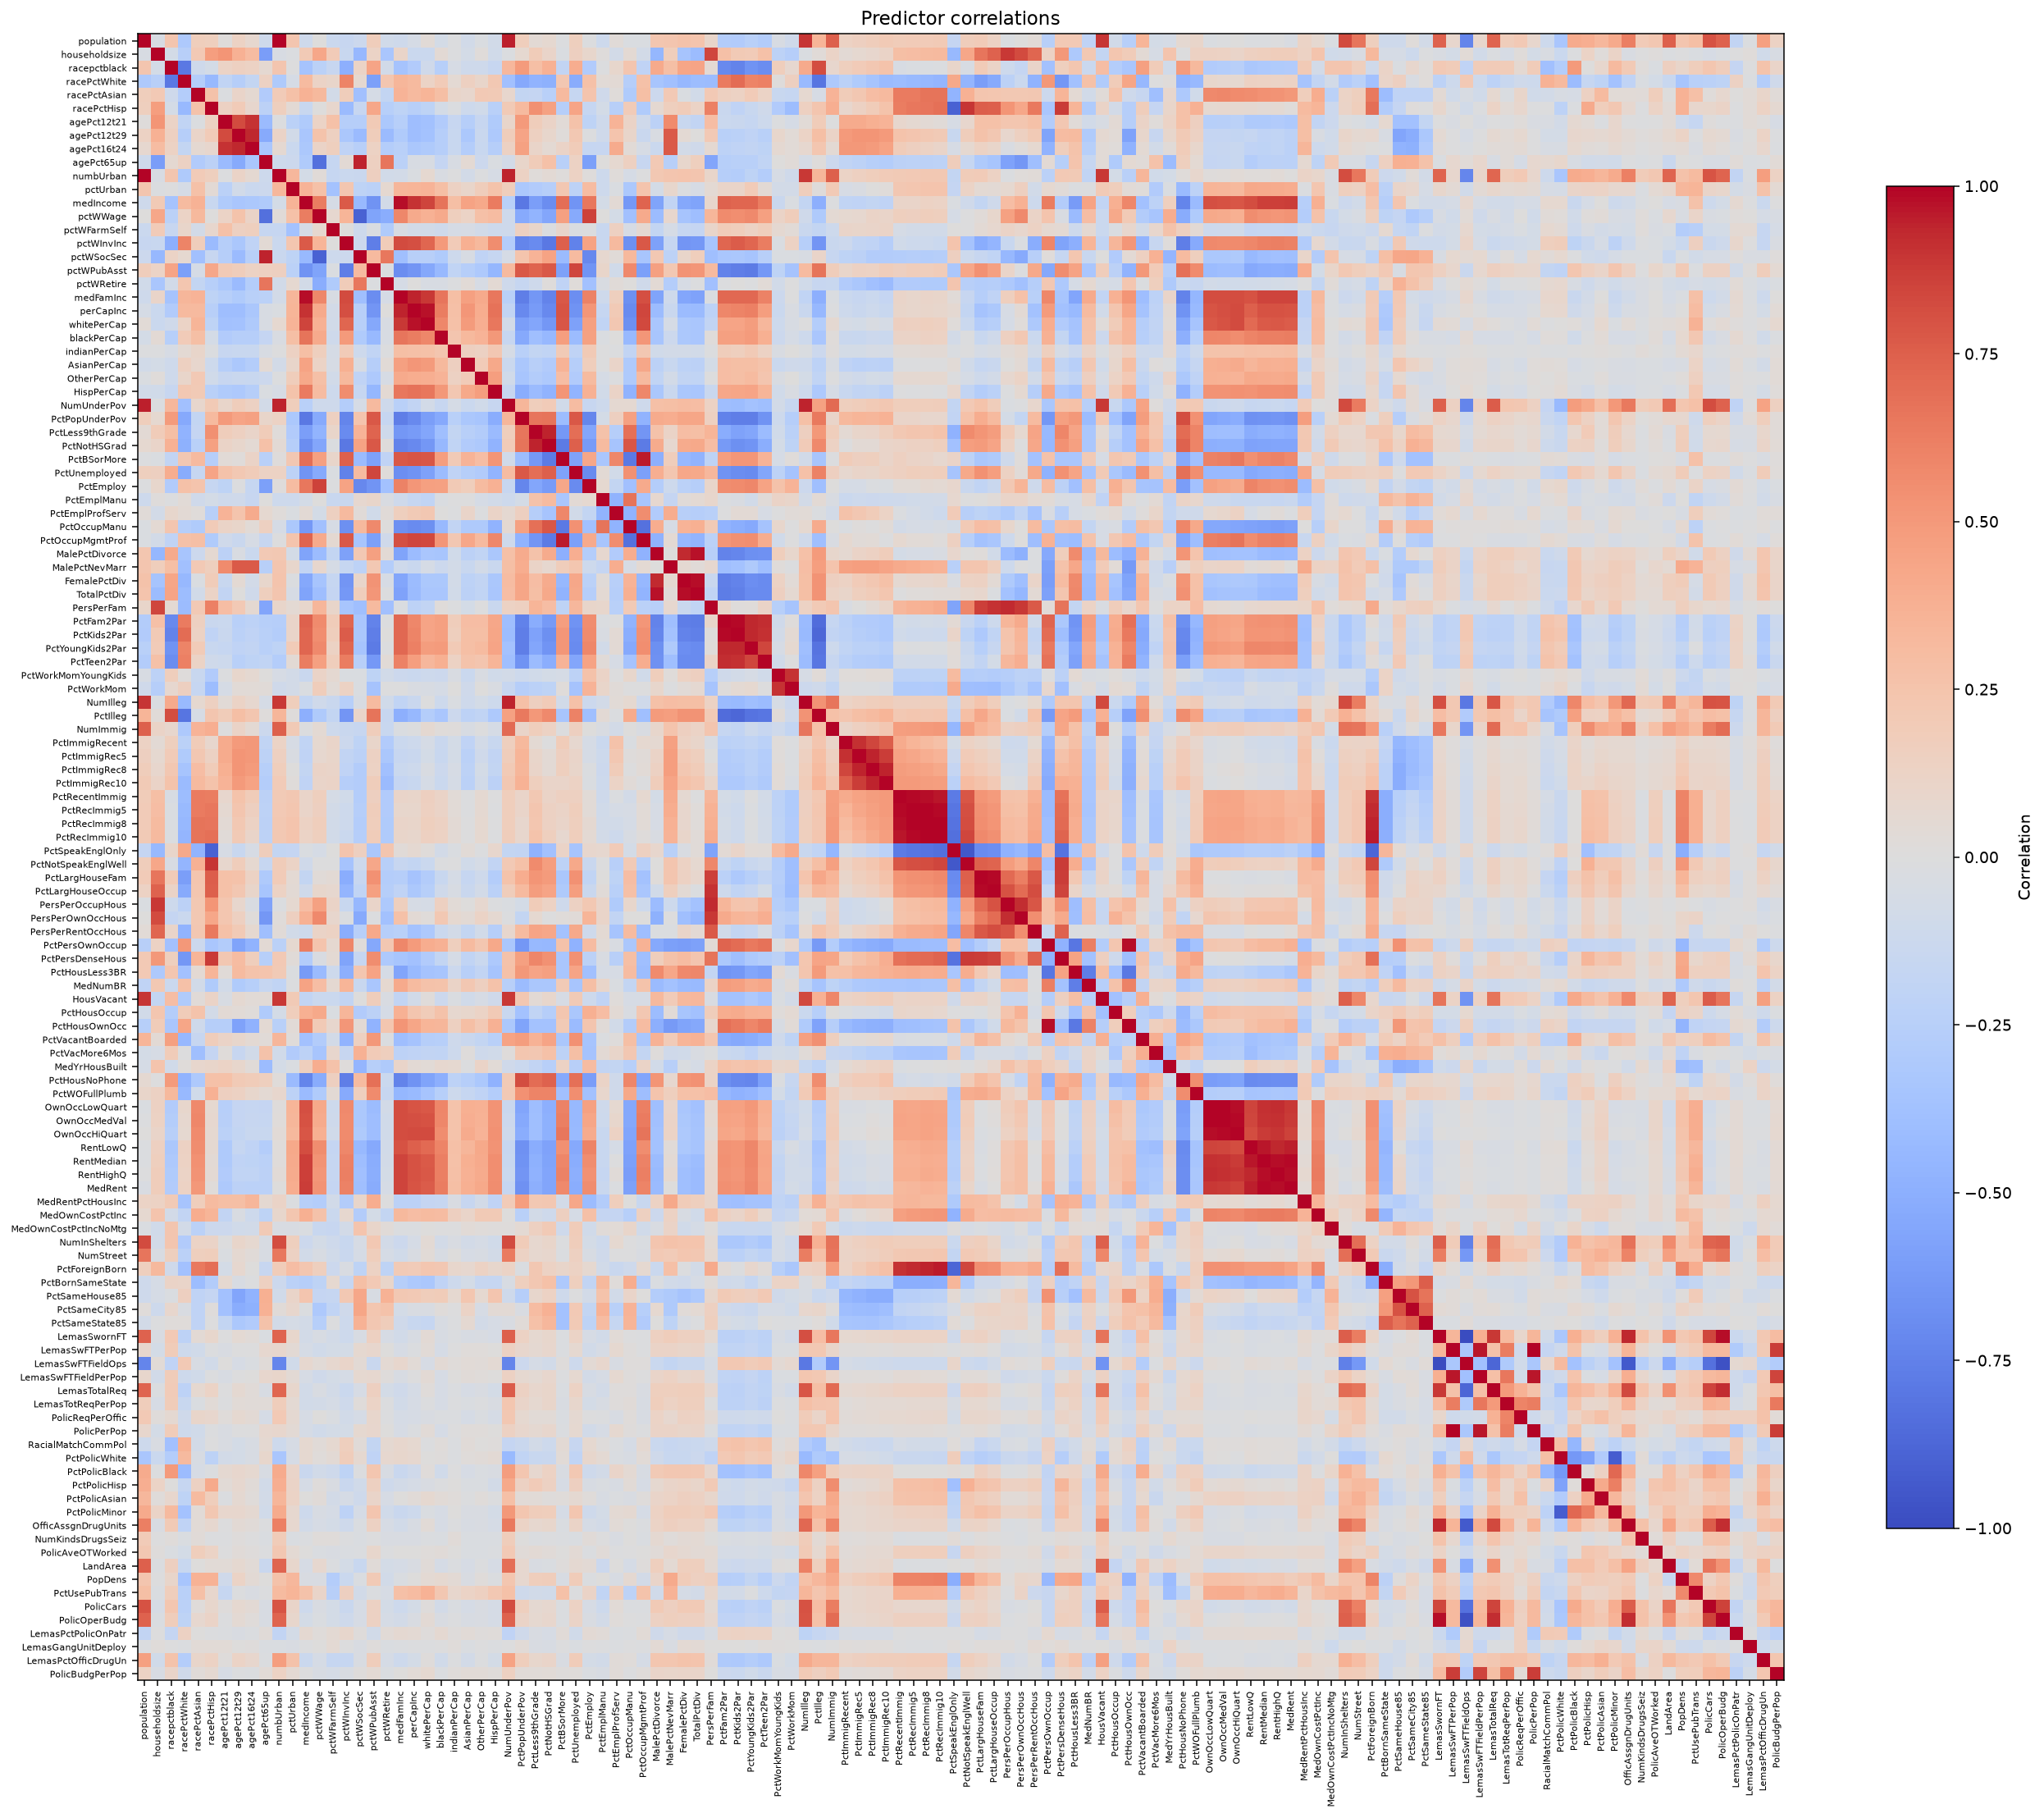

In [8]:
correlation = train_filled.corr()
fig, ax = plt.subplots(figsize=(20, 18))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=90, fontsize=6)
ax.set_yticks(range(len(correlation)), correlation.index, fontsize=6)
ax.set_title("Predictor correlations")
fig.colorbar(image, ax=ax, shrink=0.7, label="Correlation")
fig.tight_layout()
plt.show()

## 2(d) Coefficient of variation

CV = sample standard deviation / sample mean.

In [9]:
feature_cv = train_filled.std(ddof=1) / train_filled.mean()
feature_cv = feature_cv.sort_values(ascending=False)
display(feature_cv.to_frame("CV"))

,CV
PctPolicAsian,5.52706
NumStreet,4.29292
NumInShelters,3.47095
NumIlleg,3.05896
NumImmig,2.92664
LemasPctOfficDrugUn,2.55295
NumUnderPov,2.34244
LemasSwornFT,2.24804
population,2.24110
numbUrban,2.03846


## 2(e) Features with the highest CV

The requested number is floor(sqrt(128)) = 11.

,CV
PctPolicAsian,5.52706
NumStreet,4.29292
NumInShelters,3.47095
NumIlleg,3.05896
NumImmig,2.92664
LemasPctOfficDrugUn,2.55295
NumUnderPov,2.34244
LemasSwornFT,2.24804
population,2.24110
numbUrban,2.03846


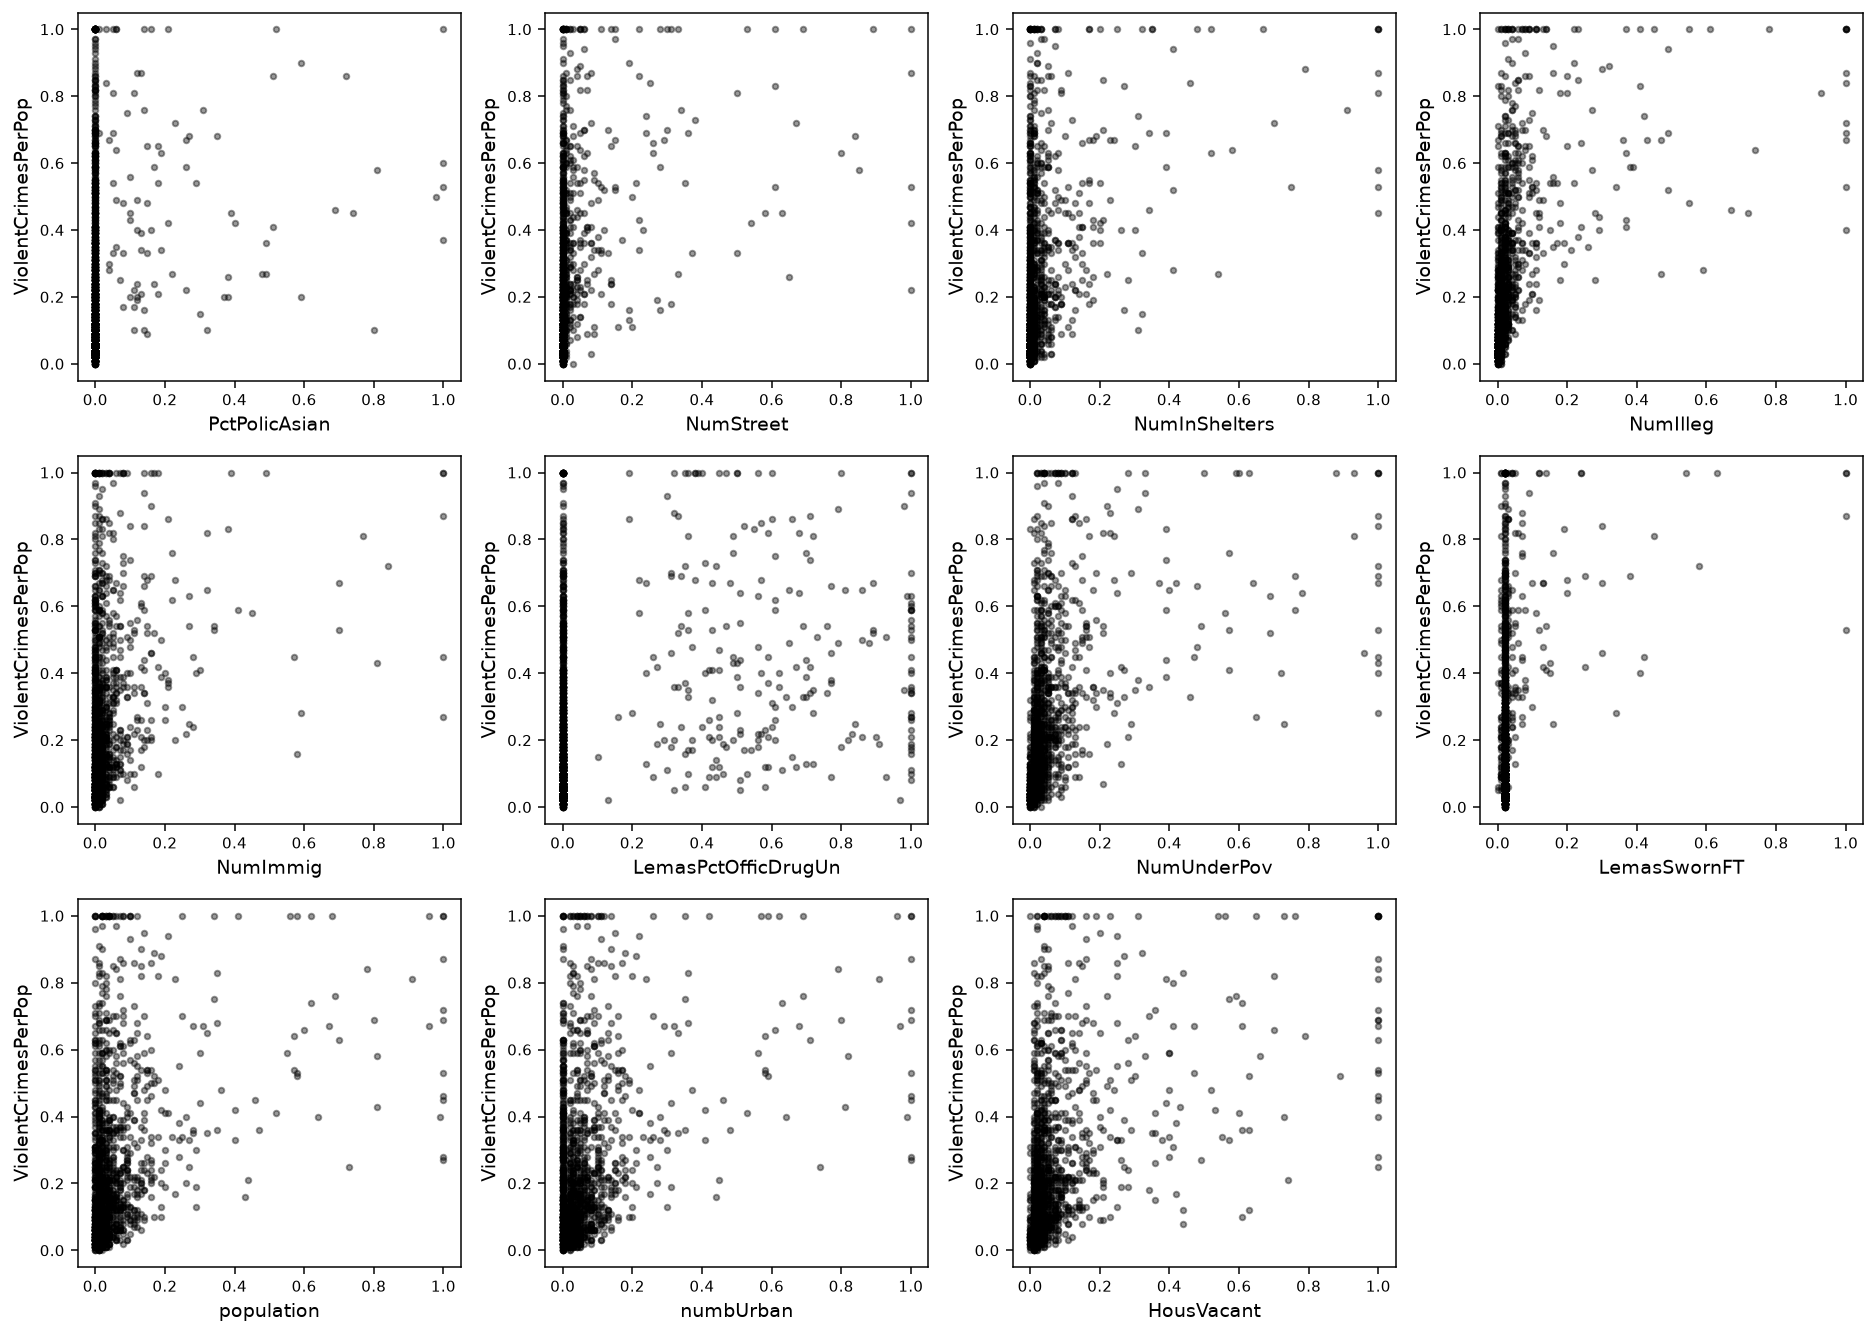

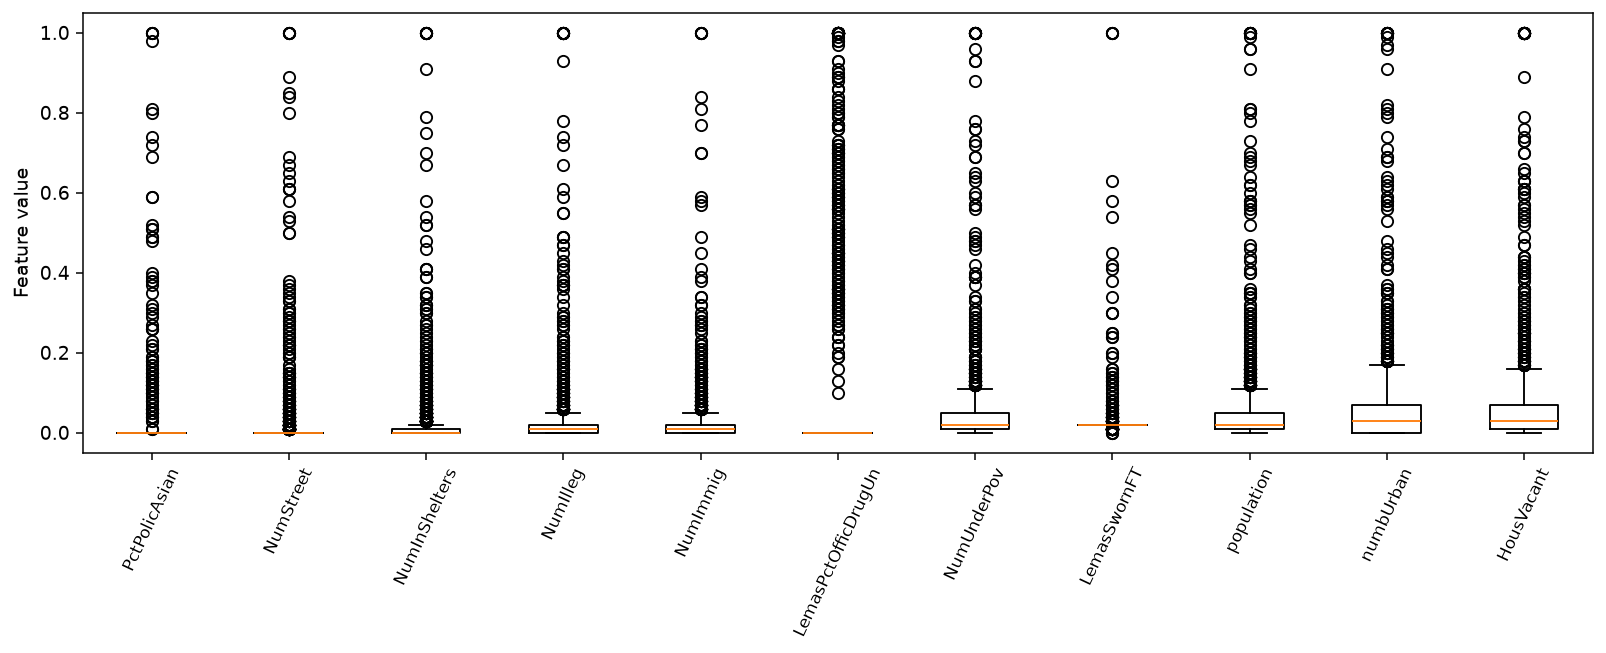

In [10]:
top_features = feature_cv.head(int(np.sqrt(128))).index
display(feature_cv.loc[top_features].to_frame("CV"))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(train_filled[feature], y_train, s=9, color="black", alpha=0.4)
    ax.set(xlabel=feature, ylabel="ViolentCrimesPerPop")
    ax.tick_params(labelsize=8)
axes.flat[-1].axis("off")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([train_filled[feature] for feature in top_features],
            tick_labels=top_features)
ax.tick_params(axis="x", labelrotation=65, labelsize=9)
ax.set_ylabel("Feature value")
fig.tight_layout()
plt.show()

The plots show skewness and possible relationships, but they cannot establish statistical significance. A high CV measures relative variation, not predictive importance.

## 2(f) Least squares

Test error is MSE. Tuning uses five-fold cross-validation on the training rows, with imputation and scaling fitted within each fold. Ridge and PCR use standardized predictors.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=552)
least_squares = LinearRegression()
least_squares.fit(train_filled, y_train)
ols_mse = mean_squared_error(y_test, least_squares.predict(test_filled))
print("Test MSE:", round(ols_mse, 6))

Test MSE: 0.017966


## 2(g) Ridge regression

In [12]:
ridge_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("ridge", Ridge())
])
ridge_search = GridSearchCV(
    ridge_model, {"ridge__alpha": np.logspace(-4, 4, 41)},
    cv=cv, scoring="neg_mean_squared_error"
)
ridge_search.fit(X_train, y_train)
ridge_mse = mean_squared_error(y_test, ridge_search.predict(X_test))
print("Selected lambda:", ridge_search.best_params_["ridge__alpha"])
print("Test MSE:", round(ridge_mse, 6))

Selected lambda: 63.09573444801943
Test MSE: 0.01746


## 2(h) Lasso with original and standardized features

In [13]:
lasso_alphas = np.logspace(-5, 0, 51)
lasso_searches = {}
lasso_rows = []
selected_features = {}
for name, scale in [("Original", "passthrough"), ("Standardized", StandardScaler())]:
    model = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", scale),
        ("lasso", Lasso(max_iter=20000))
    ])
    search = GridSearchCV(model, {"lasso__alpha": lasso_alphas},
                           cv=cv, scoring="neg_mean_squared_error")
    search.fit(X_train, y_train)
    lasso_searches[name] = search
    coefficients = search.best_estimator_.named_steps["lasso"].coef_
    selected_features[name] = X_train.columns[coefficients != 0].tolist()
    mse = mean_squared_error(y_test, search.predict(X_test))
    lasso_rows.append([name, search.best_params_["lasso__alpha"],
                       len(selected_features[name]), mse])

lasso_results = pd.DataFrame(lasso_rows, columns=["Features", "lambda",
                                                 "Selected count", "Test MSE"])
display(lasso_results.set_index("Features"))
display(pd.DataFrame({name: pd.Series(features)
                      for name, features in selected_features.items()}).fillna(""))

,lambda,Selected count,Test MSE
Features,,,
Original,0.00010,75,0.01766
Standardized,0.00063,76,0.01772


,Original,Standardized
0,racepctblack,racepctblack
1,racePctAsian,racePctAsian
2,agePct12t21,agePct12t21
3,agePct12t29,agePct12t29
4,agePct65up,pctUrban
5,pctUrban,pctWWage
6,pctWWage,pctWFarmSelf
7,pctWFarmSelf,pctWInvInc
8,pctWInvInc,pctWSocSec
9,pctWSocSec,pctWPubAsst


The original features give a lower test MSE here. Scaling changes the L1 penalty applied to each predictor, so the selected variables can differ.

## 2(i) Principal component regression

In [14]:
pcr_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression())
])
pcr_search = GridSearchCV(
    pcr_model, {"pca__n_components": list(range(1, X_train.shape[1] + 1))},
    cv=cv, scoring="neg_mean_squared_error"
)
pcr_search.fit(X_train, y_train)
pcr_mse = mean_squared_error(y_test, pcr_search.predict(X_test))
print("Selected M:", pcr_search.best_params_["pca__n_components"])
print("Test MSE:", round(pcr_mse, 6))

Selected M: 93
Test MSE: 0.018264


## 2(j) L1-regularized boosting

XGBoost's reg_alpha applies an L1 penalty to leaf weights.

In [15]:
boosting_model = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("boosting", XGBRegressor(
        objective="reg:squarederror", n_estimators=300, max_depth=3,
        learning_rate=0.05, reg_lambda=1, tree_method="hist",
        random_state=552, n_jobs=2
    ))
])
boosting_search = GridSearchCV(
    boosting_model, {"boosting__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring="neg_mean_squared_error"
)
boosting_search.fit(X_train, y_train)
boosting_mse = mean_squared_error(y_test, boosting_search.predict(X_test))
print("Selected alpha:", boosting_search.best_params_["boosting__reg_alpha"])
print("Test MSE:", round(boosting_mse, 6))

Selected alpha: 1
Test MSE: 0.01624
